-   1.开场串联+复盘
    -   1.1开场三问
        -   1.1.1昨天（11/5）学了什么？今天和它什么关系？
            -   昨天学习点散射体仿真+平面波DAS出第一张B图，B图=发射回波→各阵元按照时延对齐求和→出图
            -   今天将平面波升级为多角度平面波复合，做出低质量/高质量的两张图
        -   1.1.2今天这块在整条项目链的哪个位置？
            -   数据（多角度仿真）→波束形成→低质B图+高质B图→DL重建→指标
    -   1.2复盘
        -   1.2.1 DAS 时延公式里 z 和 sqrt(...) 各代表哪段路程？
            -   z是发射，从探头到深度z的路程；sqrt是回波从（x，z）到阵元i的路程
        -   1.2.2为什么散射体位置亮、别处暗
            -   散射体各处阵元时延对齐，相干叠加增强亮度提高，别处时延错开，相互抵消，暗
        -   1.2.3阵元数 N 从 64 减到 16，横向分辨率怎么变？
            -  横向分辨率 λz/D ，阵元数N减少，孔径变小，横向分辨率变大，能区分的两个点的距离变大，所以分辨能力变差，亮点横向变宽

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ===== 参数（复用昨天）=====
c = 1540.0
fs = 40e6
N = 64
pitch = 0.3e-3
sigma = 0.05e-6
elem_x = (np.arange(N) - (N - 1) / 2) * pitch

scatterers = np.array([
    [ 0.0e-3, 15e-3, 1.0],
    [ 3.0e-3, 20e-3, 0.7],
    [-3.0e-3, 25e-3, 0.5],
])

z_max = 40e-3
t_axis = np.arange(0, 2 * z_max / c, 1 / fs)

# ===== 多角度发射：生成 RF =====
def make_rf(theta):
    """theta（弧度）：平面波发射角度。返回 (N, T) 的 RF。"""
    rf = np.zeros((N, len(t_axis)))
    for xk, zk, amp in scatterers:
        for i in range(N):
            tau = (xk * np.sin(theta) + zk * np.cos(theta)) / c \
                + np.sqrt((xk - elem_x[i]) ** 2 + zk ** 2) / c
            rf[i] += amp * np.exp(-((t_axis - tau) ** 2) / (2 * sigma ** 2))
    return rf


-   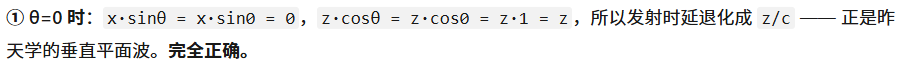
-   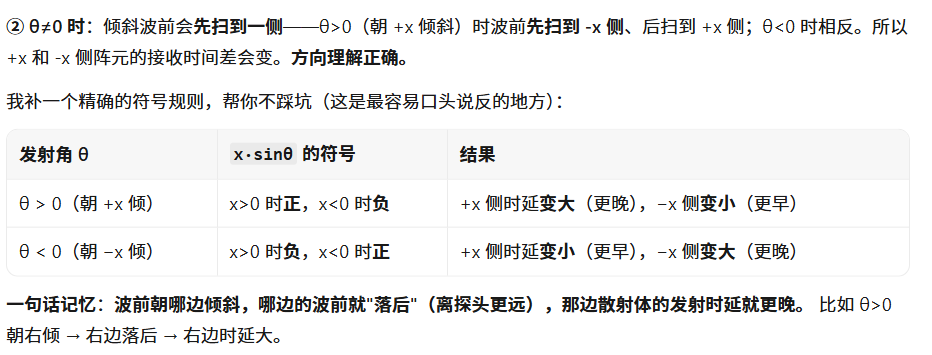

In [10]:
def das(rf, theta):
    nx, nz = 256, 512
    x_grid = np.linspace(-10e-3, 10e-3, nx)
    z_grid = np.linspace(2e-3, 40e-3, nz)
    X, Z = np.meshgrid(x_grid, z_grid)
    image = np.zeros((nz, nx))
    for i in range(N):
        tau = (X*np.sin(theta) + Z*np.cos(theta))/c \
            + np.sqrt((X-elem_x[i])**2 + Z**2)/c
        idx = np.round(tau*fs).astype(int)
        idx = np.clip(idx, 0, len(t_axis)-1)
        image += rf[i, idx]
    return image, x_grid, z_grid



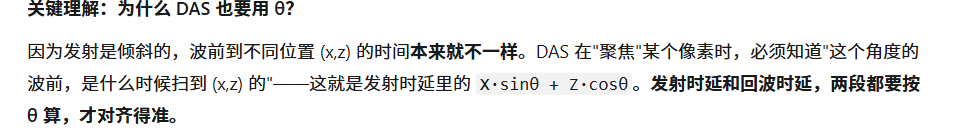

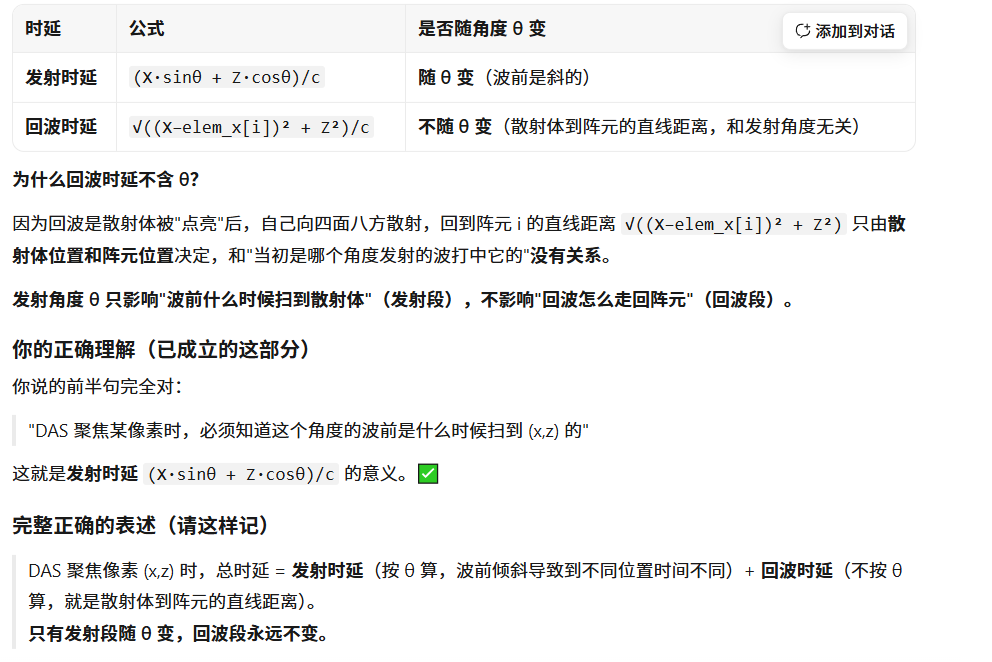

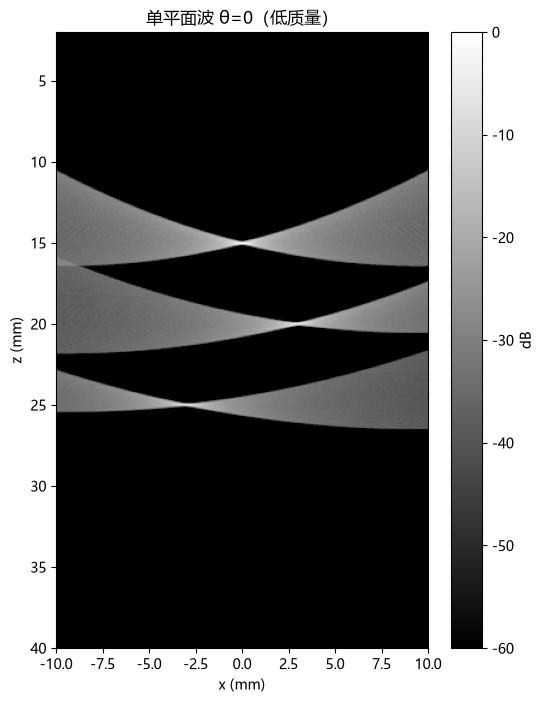

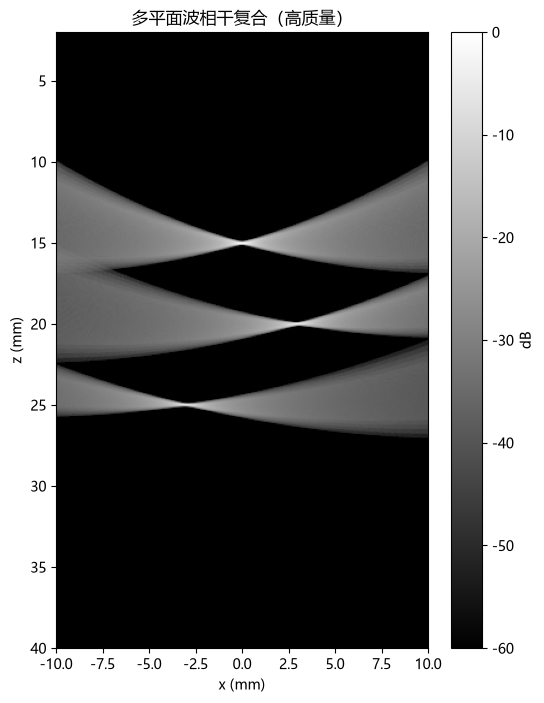

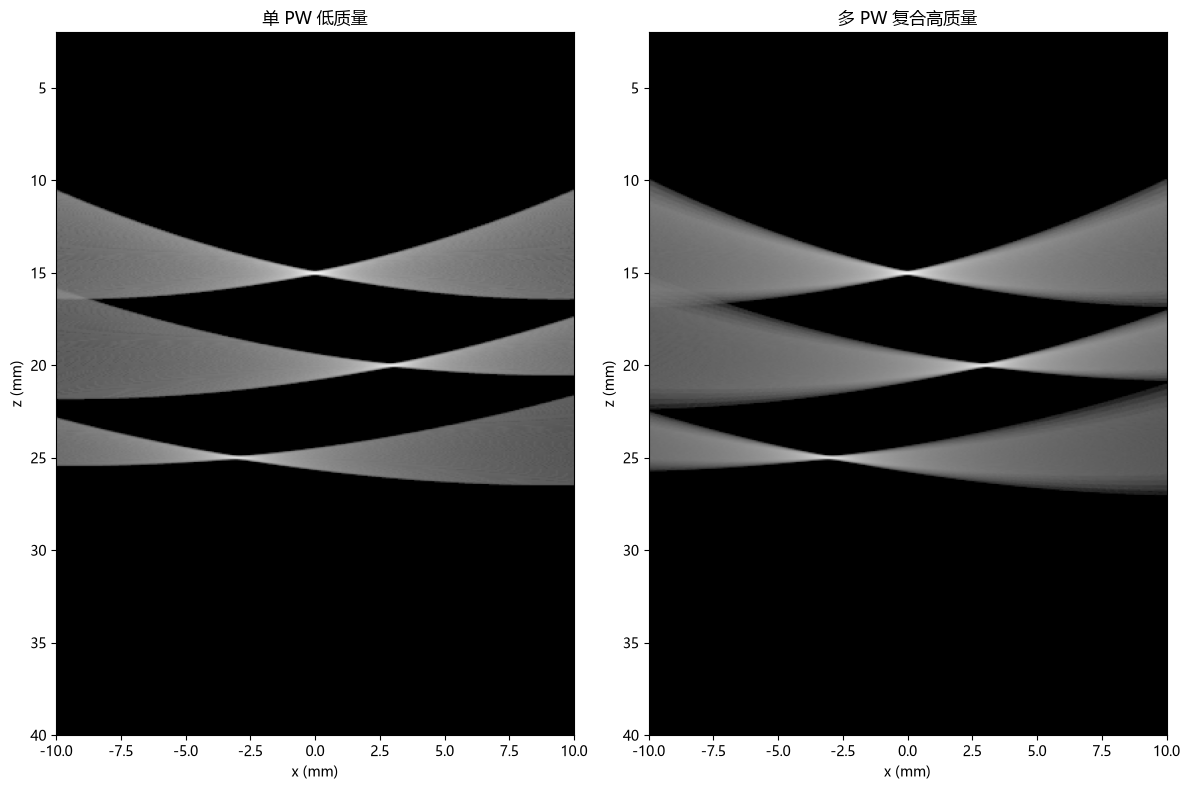

In [3]:
def disp_db(img):
    d = np.abs(img)
    return 20 * np.log10(d / d.max() + 1e-6)

def show(img, x_grid, z_grid, title):
    plt.figure(figsize=(6, 8))
    plt.imshow(disp_db(img),
               extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
               cmap="gray", aspect="auto", vmin=-60, vmax=0)
    plt.colorbar(label="dB")
    plt.xlabel("x (mm)"); plt.ylabel("z (mm)"); plt.title(title)
    plt.show()

# 单平面波（θ=0）→ 低质量图
img_low, x_grid, z_grid = das(make_rf(0.0), 0.0)
show(img_low, x_grid, z_grid, "单平面波 θ=0（低质量）")

# 多角度复合 → 高质量图
angles = np.deg2rad(np.array([-5, -2.5, 0, 2.5, 5]))   # 5 个角度（弧度）
img_comp = np.zeros_like(img_low)
for th in angles:
    img_comp += das(make_rf(th), th)[0]
img_comp /= len(angles)                                 # 平均（相干复合）
show(img_comp, x_grid, z_grid, "多平面波相干复合（高质量）")

# 并排对比
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, img, t in [(axes[0], img_low, "单 PW 低质量"), (axes[1], img_comp, "多 PW 复合高质量")]:
    ax.imshow(disp_db(img),
              extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
              cmap="gray", aspect="auto", vmin=-60, vmax=0)
    ax.set_xlabel("x (mm)"); ax.set_ylabel("z (mm)"); ax.set_title(t)
fig.tight_layout()
plt.show()


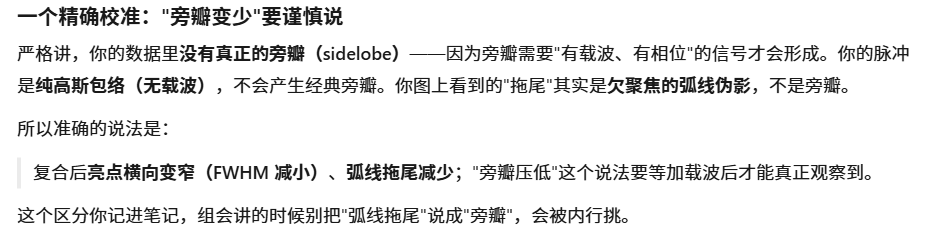

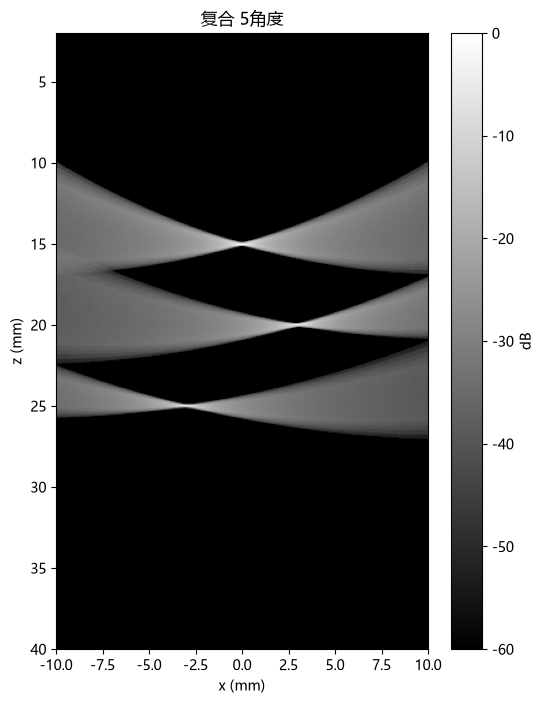

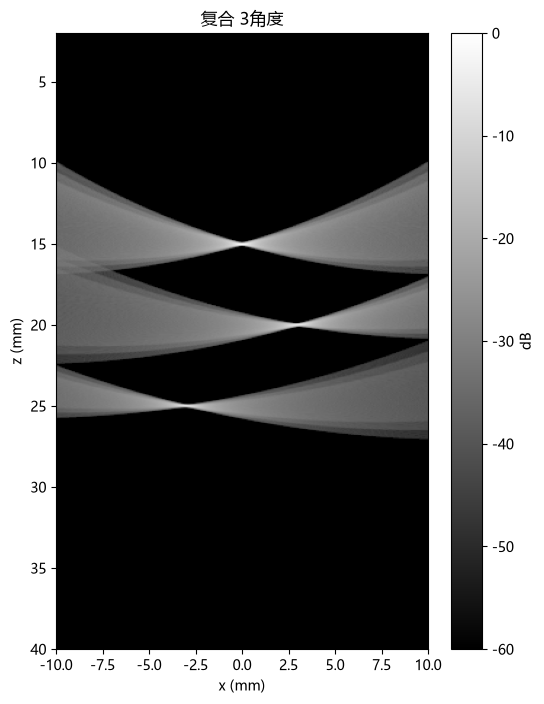

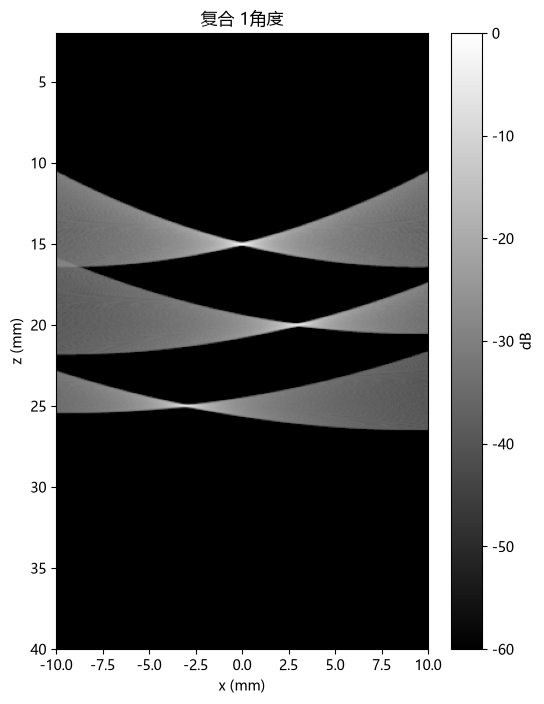

In [4]:
# ===== 变式 1：角度数量 5→3→1 =====
for label, ang in [("5角度", np.deg2rad([-5,-2.5,0,2.5,5])),
                   ("3角度", np.deg2rad([-5,0,5])),
                   ("1角度", np.deg2rad([0]))]:
    img = np.zeros_like(img_low)
    for th in ang:
        img += das(make_rf(th), th)[0]
    img /= len(ang)
    show(img, x_grid, z_grid, f"复合 {label}")


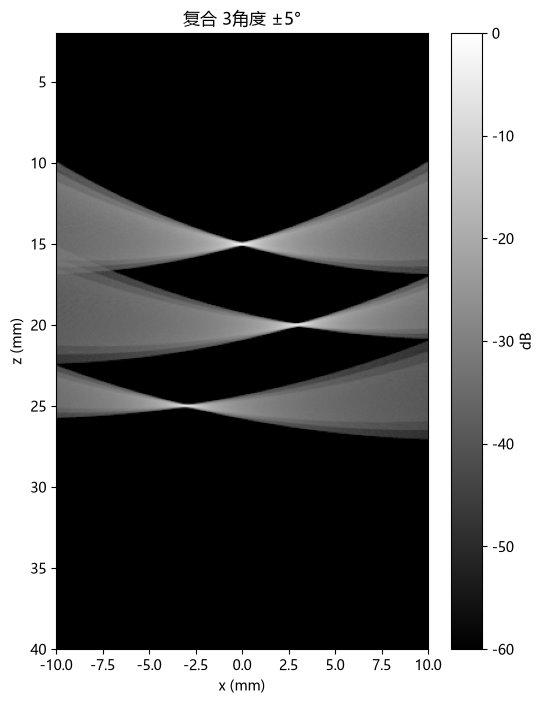

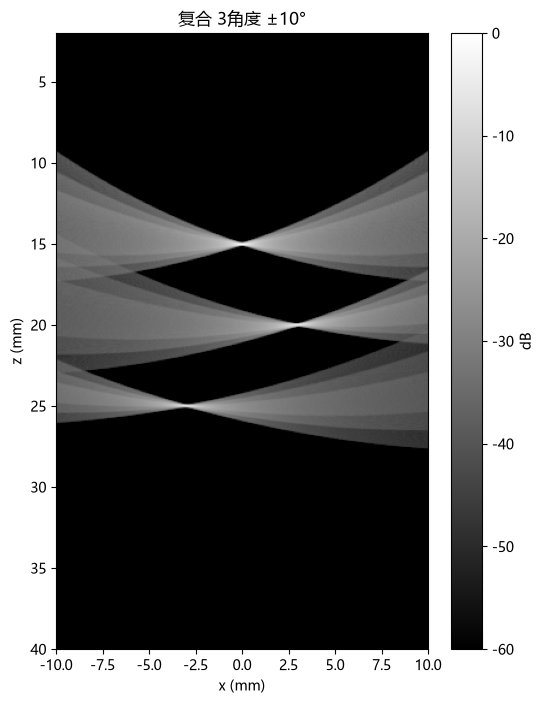

In [5]:
# ===== 变式 2：±5° vs ±10°（都是 3 个角度）=====
for label, ang in [("3角度 ±5°", np.deg2rad([-5, 0, 5])),
                   ("3角度 ±10°", np.deg2rad([-10, 0, 10]))]:
    img = np.zeros_like(img_low)
    for th in ang:
        img += das(make_rf(th), th)[0]
    img /= len(ang)
    show(img, x_grid, z_grid, f"复合 {label}")


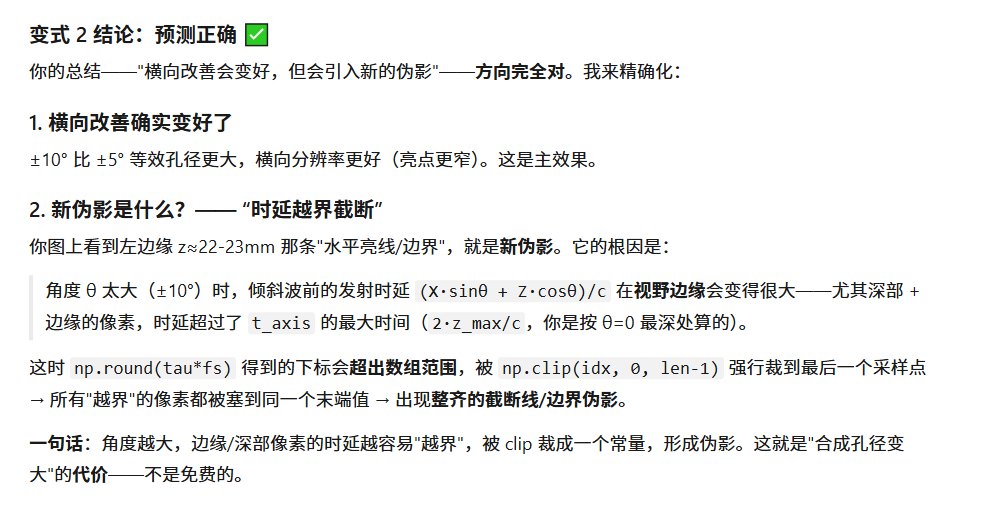
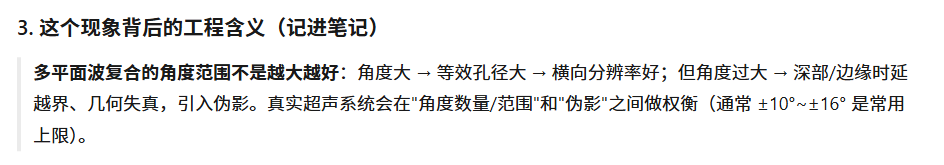

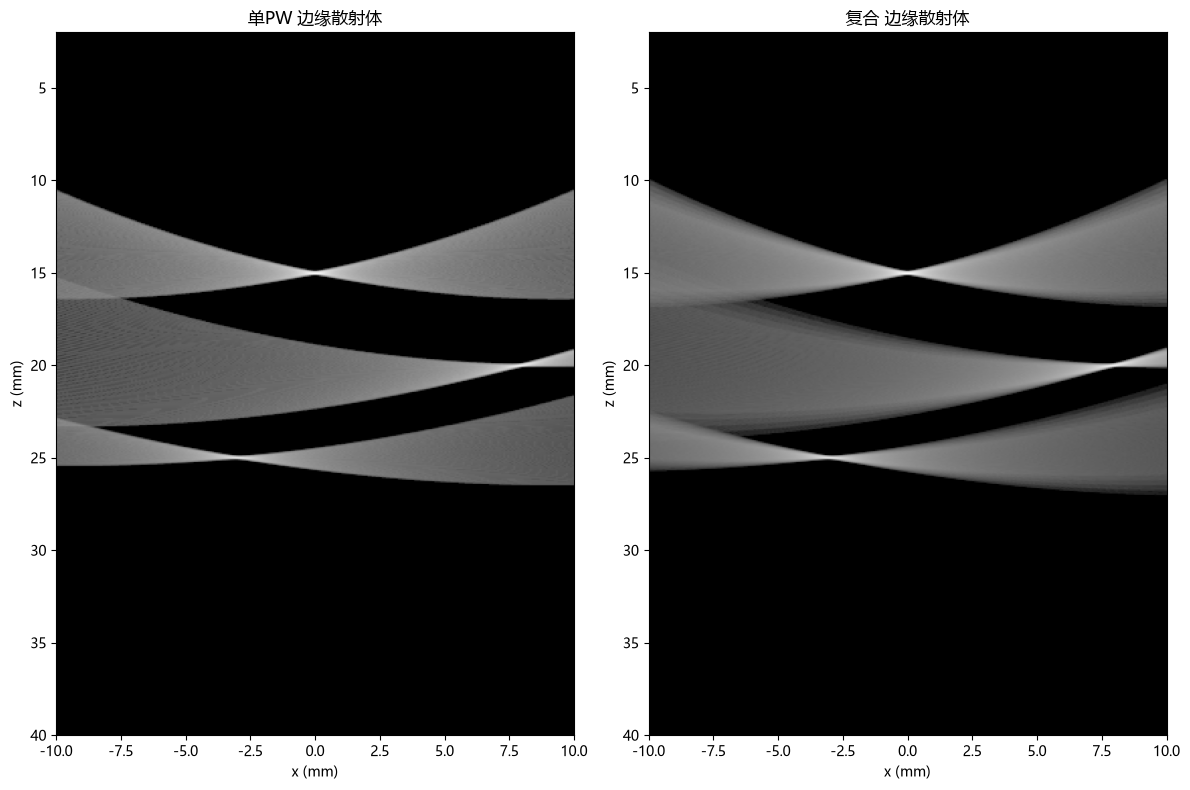

In [6]:
# ===== 变式 3：散射体 x=8mm（边缘）=====
scatterers = np.array([
    [ 0.0e-3, 15e-3, 1.0],   # 中心
    [ 8.0e-3, 20e-3, 0.7],   # 右边缘（原来 3mm 改 8mm）
    [-3.0e-3, 25e-3, 0.5],
])
# 重新跑 make_rf 和 das（因为 scatterers 变了）
img_low_v3, x_grid, z_grid = das(make_rf(0.0), 0.0)
angles = np.deg2rad([-5, -2.5, 0, 2.5, 5])
img_comp_v3 = np.zeros_like(img_low_v3)
for th in angles:
    img_comp_v3 += das(make_rf(th), th)[0]
img_comp_v3 /= len(angles)

# 并排对比
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, img, t in [(axes[0], img_low_v3, "单PW 边缘散射体"),
                   (axes[1], img_comp_v3, "复合 边缘散射体")]:
    ax.imshow(disp_db(img), extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
              cmap="gray", aspect="auto", vmin=-60, vmax=0)
    ax.set_xlabel("x (mm)"); ax.set_ylabel("z (mm)"); ax.set_title(t)
fig.tight_layout()
plt.show()


In [11]:
import os
import numpy as np

# ===== 用原始 3 个散射体（非变式），重新生成标准的低质/高质配对 =====
scatterers = np.array([
    [ 0.0e-3, 15e-3, 1.0],
    [ 3.0e-3, 20e-3, 0.7],
    [-3.0e-3, 25e-3, 0.5],
])

# 重新跑 make_rf 和 das（用标准 scatterers）
img_low, x_grid, z_grid = das(make_rf(0.0), 0.0)
angles = np.deg2rad(np.array([-5, -2.5, 0, 2.5, 5]))
img_comp = np.zeros_like(img_low)
for th in angles:
    img_comp += das(make_rf(th), th)[0]
img_comp /= len(angles)

# ===== 保存 =====
out_dir = "E:\\develop\\Graduate_AI\\learning-lab\\results\\day1106"
os.makedirs(out_dir, exist_ok=True)

# 存 .npy（DL 训练直接 np.load）
np.save(os.path.join(out_dir, "img_low_1pw.npy"), img_low)     # 输入（低质量）
np.save(os.path.join(out_dir, "img_high_5pw.npy"), img_comp)   # 目标（高质量）

print("低质量图 shape:", img_low.shape)
print("高质量图 shape:", img_comp.shape)
print("已保存到:", out_dir)


低质量图 shape: (512, 256)
高质量图 shape: (512, 256)
已保存到: E:\develop\Graduate_AI\learning-lab\results\day1106


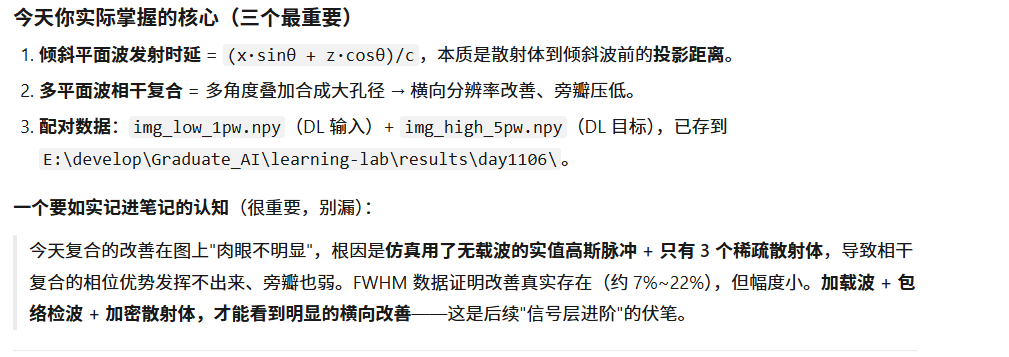

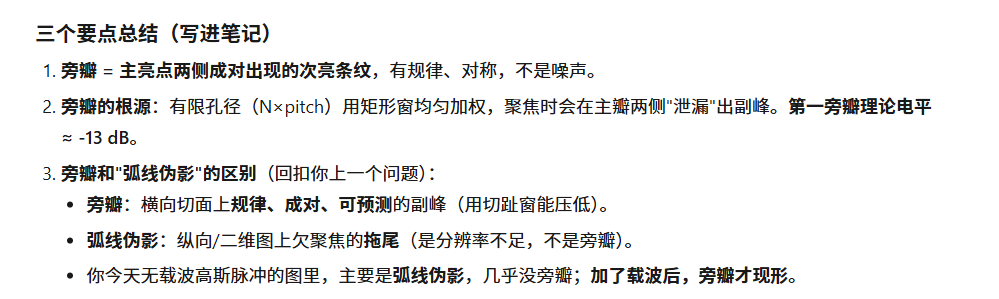